[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/walkerke/geog30323/blob/main/notebooks/assignment-06-wrangling-data-from-apis.ipynb)

## Assignment 6: Wrangling data from APIs

The previous assignment gave you some experience with the data wrangling functionality of `pandas`; these are skills you'll be returning to throughout the semester.  In this assignment, you'll be expanding upon those skills by working with data from the City of Fort Worth's Open Data API.  As you learned in class, data APIs are interfaces that allow you to access data programmatically.  In turn, data APIs allow data to be accessed by applications such as websites, or in this case a data analysis pipeline.  

Fort Worth's Open Data API is powered by [ArcGIS Hub](https://www.esri.com/en-us/arcgis/products/arcgis-hub/overview), a platform from Esri that helps cities open up their data catalogs to the public.  Many other cities use ArcGIS Hub as well.  Fort Worth's open data catalog is small, but growing, and the city's use of ArcGIS Hub makes its data available in many different ways.  

In this assignment we'll be working with Fort Worth Police crime data, available at this link: https://data.fortworthtexas.gov/datasets/5acdb612b4654c3abb30e6987db2408b/explore.  The data include observations going back more than 50 years!  However, we'll be working with more recent data as we can presume that they are more complete.  

The ArcGIS Hub web interface includes a lot of options for filtering, manipulating, and visualizing the data.  As we want to be able to access it inside our data analysis environment in `pandas`, however, we'll want to be able to access it directly.  ArcGIS Hub gives several options for exporting the data in a variety of formats, including CSV; however, you are going to learn in this assignment how to access the data through the city's open data API.  

Generally, data APIs make data available in one of two formats: JSON (**J**ava**S**cript **O**bject **N**otation) or XML (e**X**tensible **M**arkup **L**anguage).  JSON is becoming the more common of the two, as it fits well within the structure of modern websites, which rely heavily on the JavaScript programming language.  

JSON is a way of encoding data objects with JavaScript, and organizes data as a series objects represented by key-value pairs.  In terms of how you are used to thinking about data, the __object__ represents a record, the __key__ represents a column header, and the __value__ represents a data value.  Let's take a look at a single JSON record from the crime database (run the cell to display it if it doesn't show): 

In [1]:
from IPython.display import IFrame

IFrame("https://services5.arcgis.com/3ddLCBXe1bRt7mzj/arcgis/rest/services/CFW_Open_Data_Police_Crime_Data_Table_view/FeatureServer/0/query?where=Case_No%3D%27250090795%27&outFields=Case_No,Reported_Date,Nature_Of_Call,BLOCK_ADDRESS,CouncilDistrict&f=pjson", width = 700, height = 450)

The code you see above is new: I'm using the capabilities of the Jupyter Notebook to display an embedded web page.  Trust me, we haven't even scratched the surface of what the Notebook can do; it can display animated GIFs, YouTube videos, interactive charts/maps, and much more!  Here, I'm showing the contents of the URL https://services5.arcgis.com/3ddLCBXe1bRt7mzj/arcgis/rest/services/CFW_Open_Data_Police_Crime_Data_Table_view/FeatureServer/0/query?where=Case_No%3D%27250090795%27&outFields=Case_No,Reported_Date,Nature_Of_Call,BLOCK_ADDRESS,CouncilDistrict&f=pjson - click it to take a look if you want - which queries Fort Worth's open data API and returns a single record from the crime dataset.  Let's break the URL down a little bit.  

The first part, https://services5.arcgis.com/3ddLCBXe1bRt7mzj/arcgis/rest/services/CFW_Open_Data_Police_Crime_Data_Table_view/FeatureServer/0/query, is the __API endpoint__.  This is the root directory of the data API, where our requests for the crime data are sent.  The second part, beginning with `?where=Case_No='250090795'`, is a __filter__; the question mark signifies that I am going to query the data, and the string that follows, `Case_No='250090795'`, specifies how the data are to be subsetted.  The other parameters, separated by `&`, ask for five of the columns (`outFields=Case_No,Reported_Date,Nature_Of_Call,BLOCK_ADDRESS,CouncilDistrict`) in JSON format (`f=pjson`).  I've done this all in the URL of the API call!

The response has two parts.  `"fields"` describes each column, including its name and data type, a bit like a data dictionary.  `"features"` contains the records themselves; each record's data values are found in `"attributes"`.  Keep both of these in mind; they'll come up again later in the assignment.

Additionally, the `where` parameter of the API recognizes SQL (Structured Query Language), the language that allows users to access databases.  More information is here: https://developers.arcgis.com/rest/services-reference/enterprise/query-feature-service-layer/.  For example, the following query will return thefts in Fort Worth for 2025: 

In [2]:
# This is the API endpoint - the source of our data
endpoint = "https://services5.arcgis.com/3ddLCBXe1bRt7mzj/arcgis/rest/services/CFW_Open_Data_Police_Crime_Data_Table_view/FeatureServer/0/query"

# Here is the first part of the query - denoting what type of offense we want
type_query = "Nature_Of_Call = 'THEFT'"

# Here is the second part of the query - we are taking offenses on or after January 1, 2025, 
# and prior to January 1, 2026
date_query = " AND Reported_Date >= '2025-01-01' AND Reported_Date < '2026-01-01'"

# We then put the query into a dictionary of parameters for our API call.  
# 'outFields': '*' returns all columns; 'resultType': 'standard' allows up to 32,000 records 
# to be returned at once (the default is 1,000); and 'f': 'json' returns the data as JSON.  
params = {
    'where': type_query + date_query,
    'outFields': '*',
    'resultType': 'standard',
    'f': 'json'
}

We'll use the `requests` library to send our query to the API.  As there are spaces and special characters in the query, it needs to be translated to the string a web browser would use; `requests` handles this for us.  Take a look at the URL it builds: 

In [3]:
import pandas as pd
import requests

response = requests.get(endpoint, params = params)

response.url

'https://services5.arcgis.com/3ddLCBXe1bRt7mzj/arcgis/rest/services/CFW_Open_Data_Police_Crime_Data_Table_view/FeatureServer/0/query?where=Nature_Of_Call+%3D+%27THEFT%27+AND+Reported_Date+%3E%3D+%272025-01-01%27+AND+Reported_Date+%3C+%272026-01-01%27&outFields=%2A&resultType=standard&f=json'

The `.json()` method translates the response into Python dictionaries and lists.  The records themselves are found in the `'features'` element; a list comprehension pulls the `'attributes'` of each record out, and `pd.DataFrame()` turns them into a new data frame called `theft_df`.  

In [4]:
data = response.json()

theft_df = pd.DataFrame([f['attributes'] for f in data['features']])

theft_df.shape

(11917, 19)

Our API call has returned nearly 12,000 theft calls in Fort Worth in 2025.  Let's take a quick peek at the data: 

In [5]:
theft_df.head()

,Case_No_Offense,Case_No,Reported_Date,Nature_Of_Call,From_Date,Offense,Offense_Desc,BLOCK_ADDRESS,City,State,Beat,Division,CouncilDistrict,Attempt_Complete,Location_Type,LocationTypeDescription,intTotal,Location_1,ObjectId
0,250089045-23,25008904,2025-11-24T00:30:00,THEFT,2025-11-18T13:00:00,23H,PC 31.03(e)(2)(A) Theft Property >=$100<$750,4100 AIRPORT FWY,FORT WORTH,TX,A13,NaN,11,C,7.0,07 CONVENIENCE STORE,0,"(32.775660705690548, -97.287510573265365)",105
1,220074885-26A,220074885,2025-01-06T05:08:00,THEFT,2025-01-06T05:08:00,26A,PC 32.55(d)(6) FINANCIAL ABUSE ELDERLY >=$150K,300 W BELKNAP ST,FORT WORTH,Te,A16,NaN,9,C,20.0,20 RESIDENCE/HOME,0,"(32.89283981132138, -97.302715710753986)",1217105
2,230011993-23H,230011993,2025-02-17T08:25:00,THEFT,2025-02-13T22:20:00,23H,PC 31.03(E)(4)(A) Theft>$1500<$20K,5700 OAKLEY AVE,FORT WORTH,Te,E15,North,10,C,20.0,20 RESIDENCE/HOME,0,"(32.935578499448255, -97.259713400222935)",1245608
3,230318026-23C,230318026,2025-02-16T03:44:00,THEFT,2023-06-29T21:00:00,23C,PC 31.03 Theft - Shoplifting,1100 EASTCHASE PKWY,FORT WORTH,TX,H12,East,5,C,24.0,24 SPECIALTY STORE,0,NaN,1297255
4,240001145-23C,240001145,2025-01-05T15:06:00,THEFT,2024-12-30T13:28:00,23C,GC 085-07 Theft under $100- Shoplifting,7900 SOUTH FWY,FORT WORTH,TX,I18,South,8,C,24.0,24 SPECIALTY STORE,0,"(32.634589813124343, -97.321709532507086)",1301204


Notice how `pandas` has translated the JSON into a data frame with columns that make sense to us.  There is a lot we can do with the data here!  We have information about the date of the crime; the location - including lat/long coordinates, that need some additional parsing - the police beat, and the city council district.  Using the methods we've learned to this point, we can do some basic analysis of the data.  For example: how did theft vary by city council district in 2025?  

In [6]:
theft_by_district = theft_df.groupby('CouncilDistrict')

theft_by_district.size()

CouncilDistrict
10     658
11    1211
2      898
3     1275
4      935
5     1326
6     1366
7      612
8     1463
9     1692
dtype: int64

Looks like District 9 had the most thefts, followed by District 8.  Let's try plotting this with `seaborn`: 

<Axes: xlabel='count', ylabel='CouncilDistrict'>

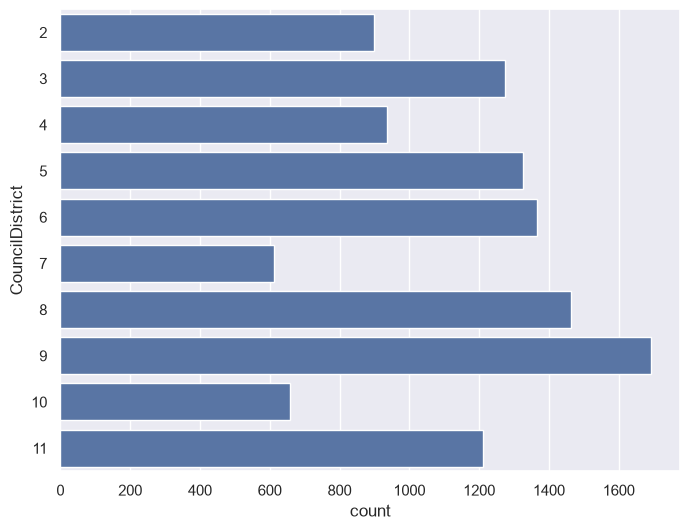

In [7]:
import seaborn as sns
sns.set_theme(style = "darkgrid", rc = {"figure.figsize": (8, 6)})

sns.countplot(data = theft_df, y = 'CouncilDistrict', 
              order = ['2', '3', '4', '5', '6', '7', '8', '9', '10', '11'])

A trained observer, however, would notice that that data are not normalized for population.  As data analysts, always be mindful of whether your analysis accurately represents the underlying variation in your data.  Data can easily mislead if not presented correctly; for example, while the largest cities in the United States will usually have the most crimes, they won't necessarily have the highest crime __rates__.  

However, we don't have city council district population in our dataset; in turn, we'll need to fetch it from somewhere else and __merge__ it to our existing data.  As we discussed in class, merges are based on __key fields__ that match between two different tables.  Also, recall from class our discussion of the four types of merges available to you in `pandas` via the `.merge()` method, which can be passed as arguments to the `how` parameter: 

* `'inner'` (the default): only the matching rows are retained
* `'left'`: all rows from the first table are retained; only matching rows from the second table are retained
* `'right'`: all rows from the second table are retained; only matching rows from the first table are retained
* `'outer'`: all rows are retained, regardless of a match between the two tables

We'll be conducting a very simple merge here, in which all rows will match between the two tables.  Let's read in the city council population data (from the 2020 Census, for the current council districts) from our course GitHub repository:  

In [8]:
council = pd.read_csv('https://raw.githubusercontent.com/walkerke/geog30323/main/data/cd_population.csv')

council

,name,total,district
0,2 - Carlos Flores,89699,2
1,3 - Michael D. Crain,86783,3
2,4 - Charles Lauersdorf,94350,4
3,5 - Deborah Peoples,94935,5
4,6 - Mia Hall,87751,6
5,7 - Macy Hill,95456,7
6,8 - Chris Nettles,92649,8
7,9 - Elizabeth M. Beck,86668,9
8,10 - Chris Jamieson,95643,10
9,11 - Jeanette Martinez,95148,11


We can now create a data frame from our `groupby` result (resetting the index, as `pandas` places the group name in the index), to get it ready for a merge.  

In [9]:
theft_by_district_df = pd.DataFrame(theft_by_district.size().reset_index())

theft_by_district_df.columns = ['district', 'count']

theft_by_district_df

,district,count
0,10,658
1,11,1211
2,2,898
3,3,1275
4,4,935
5,5,1326
6,6,1366
7,7,612
8,8,1463
9,9,1692


We'll be able to merge on the "district" column, which I've renamed in the second data frame for clarity.  First, let's check our `dtypes` to make sure they match up: 

In [10]:
council.dtypes

name          str
total       int64
district    int64
dtype: object

In [11]:
theft_by_district_df.dtypes

district      str
count       int64
dtype: object

The `district` column is stored as integers in `council`, but as text in `theft_by_district_df` - the district numbers came from the API as strings.  The `"fields"` section of the API response told us this at the start: `CouncilDistrict` is listed as `esriFieldTypeString`.  `pandas` will not merge on columns of two different types, so we'll convert it to integers first with the `.astype()` method: 

In [12]:
theft_by_district_df['district'] = theft_by_district_df['district'].astype(int)

theft_by_district_df.dtypes

district    int64
count       int64
dtype: object

Now, we can do the merge with the `.merge()` method in `pandas`.  

In [13]:
council_merged = council.merge(theft_by_district_df, on = 'district', how = "left")

council_merged

,name,total,district,count
0,2 - Carlos Flores,89699,2,898
1,3 - Michael D. Crain,86783,3,1275
2,4 - Charles Lauersdorf,94350,4,935
3,5 - Deborah Peoples,94935,5,1326
4,6 - Mia Hall,87751,6,1366
5,7 - Macy Hill,95456,7,612
6,8 - Chris Nettles,92649,8,1463
7,9 - Elizabeth M. Beck,86668,9,1692
8,10 - Chris Jamieson,95643,10,658
9,11 - Jeanette Martinez,95148,11,1211


Perfect!  We can now calculate a new column that measures rate per 1000 residents for thefts in 2025.

In [14]:
council_merged['rate'] = (council_merged['count'] / council_merged['total']) * 1000

council_merged

,name,total,district,count,rate
0,2 - Carlos Flores,89699,2,898,10.011260
1,3 - Michael D. Crain,86783,3,1275,14.691818
2,4 - Charles Lauersdorf,94350,4,935,9.909910
3,5 - Deborah Peoples,94935,5,1326,13.967451
4,6 - Mia Hall,87751,6,1366,15.566774
5,7 - Macy Hill,95456,7,612,6.411331
6,8 - Chris Nettles,92649,8,1463,15.790780
7,9 - Elizabeth M. Beck,86668,9,1692,19.522777
8,10 - Chris Jamieson,95643,10,658,6.879751
9,11 - Jeanette Martinez,95148,11,1211,12.727540


And we can plot the results: 

<Axes: xlabel='rate', ylabel='name'>

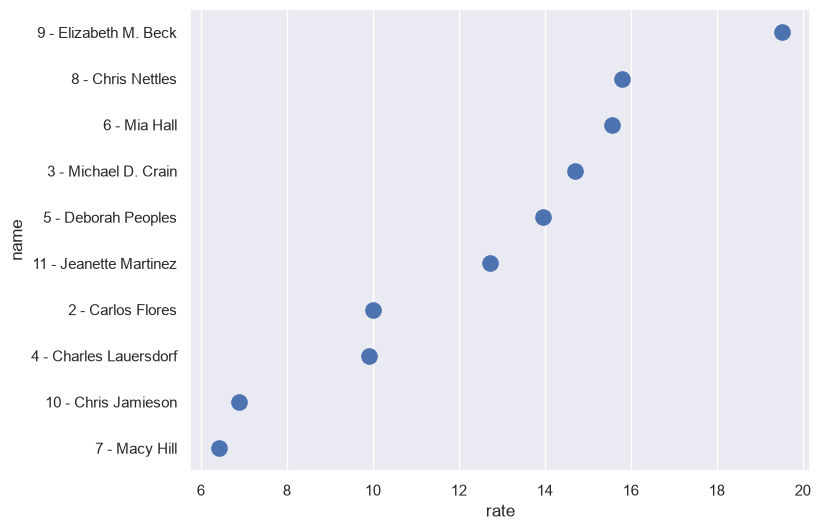

In [15]:
council_sort = council_merged.sort_values('rate', ascending = False)

sns.stripplot(data = council_sort, x = 'rate', y = 'name', size = 12)

Just in case you were wondering: TCU is split across council districts 3 and 9.  

The last thing we're going to do is look at how thefts varied by date in 2025.  We have two columns that represent dates: `From_Date` and `Reported_Date`; however they are not currently formatted as dates.  Dates are very tricky types to work with in data analysis - there are many different ways that dates can be written!  Fortunately, ours are currently fairly consistent - we just need to do a little work with them.  

The date fields in our data frame include the time of day after the `'T'` (e.g. `'T13:06:00'`); as we're interested in how thefts varied by day, we're going to remove it from the string.  

The steps below will do the following: 

* Remove the unnecessary time information, creating a new column `date1`; 
* Create a new column formatted as a date, `date2`, from `date1`, using the `to_datetime()` function in `pandas`.  

In [16]:
theft_df['date1'] = theft_df['Reported_Date'].str[:10]

theft_df['date2'] = pd.to_datetime(theft_df['date1'])

theft_df.head()

,Case_No_Offense,Case_No,Reported_Date,Nature_Of_Call,From_Date,Offense,Offense_Desc,BLOCK_ADDRESS,City,State,...,Division,CouncilDistrict,Attempt_Complete,Location_Type,LocationTypeDescription,intTotal,Location_1,ObjectId,date1,date2
0,250089045-23,25008904,2025-11-24T00:30:00,THEFT,2025-11-18T13:00:00,23H,PC 31.03(e)(2)(A) Theft Property >=$100<$750,4100 AIRPORT FWY,FORT WORTH,TX,...,NaN,11,C,7.0,07 CONVENIENCE STORE,0,"(32.775660705690548, -97.287510573265365)",105,2025-11-24,2025-11-24
1,220074885-26A,220074885,2025-01-06T05:08:00,THEFT,2025-01-06T05:08:00,26A,PC 32.55(d)(6) FINANCIAL ABUSE ELDERLY >=$150K,300 W BELKNAP ST,FORT WORTH,Te,...,NaN,9,C,20.0,20 RESIDENCE/HOME,0,"(32.89283981132138, -97.302715710753986)",1217105,2025-01-06,2025-01-06
2,230011993-23H,230011993,2025-02-17T08:25:00,THEFT,2025-02-13T22:20:00,23H,PC 31.03(E)(4)(A) Theft>$1500<$20K,5700 OAKLEY AVE,FORT WORTH,Te,...,North,10,C,20.0,20 RESIDENCE/HOME,0,"(32.935578499448255, -97.259713400222935)",1245608,2025-02-17,2025-02-17
3,230318026-23C,230318026,2025-02-16T03:44:00,THEFT,2023-06-29T21:00:00,23C,PC 31.03 Theft - Shoplifting,1100 EASTCHASE PKWY,FORT WORTH,TX,...,East,5,C,24.0,24 SPECIALTY STORE,0,NaN,1297255,2025-02-16,2025-02-16
4,240001145-23C,240001145,2025-01-05T15:06:00,THEFT,2024-12-30T13:28:00,23C,GC 085-07 Theft under $100- Shoplifting,7900 SOUTH FWY,FORT WORTH,TX,...,South,8,C,24.0,24 SPECIALTY STORE,0,"(32.634589813124343, -97.321709532507086)",1301204,2025-01-05,2025-01-05


Scroll to the end; we see that `date1` and `date2` look similar; however, `date2` is formatted as a date, which means that `pandas` recognizes how to work with it in sequence.  In turn, we can plot how thefts varied by day in Fort Worth in 2025: 

<Axes: xlabel='Date', ylabel='Number'>

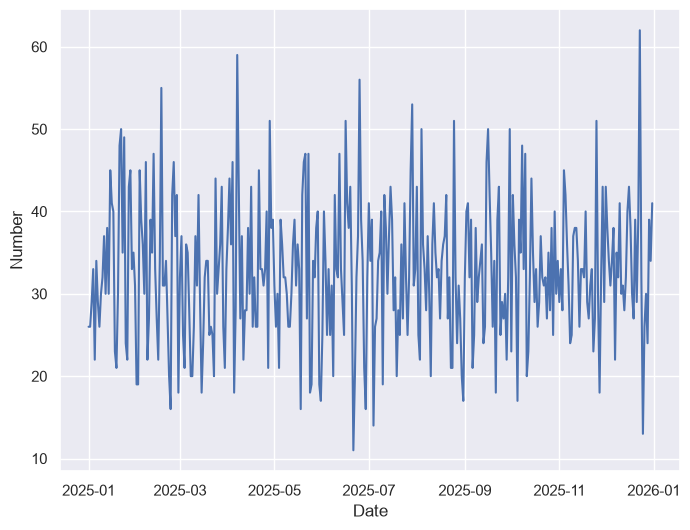

In [17]:
theft_by_date = (theft_df
                .groupby('date2')
                .size()
                .reset_index()
                )

theft_by_date.columns = ["Date", "Number"]


sns.lineplot(x = "Date", y = "Number", data = theft_by_date)

Read through the code to understand what it does.  I'm introducing you here to a new process of operations called _method chaining_ which is very popular in data programming. Rather than writing out a separate command for each method, generating new objects along the way, e.g.:

```python
theft_groupby = theft_df.groupby('date2')
theft_size = theft_groupby.size()
theft_reset = theft_size.reset_index()
```

Method chaining allows for the specification of a data wrangling process as a series of steps.  The code we use - 

```python
theft_by_date = (theft_df
                .groupby('date2')
                .size()
                .reset_index()
                )
```

can be read as "To generate the object `theft_by_date`, we first take the `theft_df` data frame, then we group it by the `"date2"` column, then we compute the size, then we reset the index."  Method chains over multiple lines like these must be wrapped in parentheses so Python knows that the methods belong to a multi-line chain.  This is the style that I often use in my projects as it helps me keep my thoughts organized.  

Once we've generated an appropriate object using the method chain, we can give it sensible column names and plot the result with `sns.lineplot()`.

One thing you may notice with the plot, however, is that it appears choppy, making it difficult to discern trends for the entire year.  An alternative way to visualize this is by re-calculating the data as a _rolling mean_, where the number associated with each date represents an average of the days around it.  __pandas__ is designed specifically for this type of time-series analysis.  

In [18]:
theft_by_date['Weekly_Avg'] = theft_by_date['Number'].rolling(window = 7, min_periods = 1).mean()

theft_by_date.head()

,Date,Number,Weekly_Avg
0,2025-01-01,26,26.0
1,2025-01-02,26,26.0
2,2025-01-03,29,27.0
3,2025-01-04,33,28.5
4,2025-01-05,22,27.2


Above, we use the `.rolling()` method to specify a "window" of observations around each row for a given column.  We can then compute a statistic (e.g. sum, mean) over that rolling window and we get back the appropriate result.  The `min_periods` argument is necessary here as the default will return `NaN` (missing data) for rows with fewer observations in their windows than the specified size.

As we've now computed the seven-day average for theft in 2025 by day, we can visualize it on a chart.  Here, we draw the seven-day average on top of the daily counts, which are made lighter with the `alpha` argument.

<Axes: xlabel='Date', ylabel='Number'>

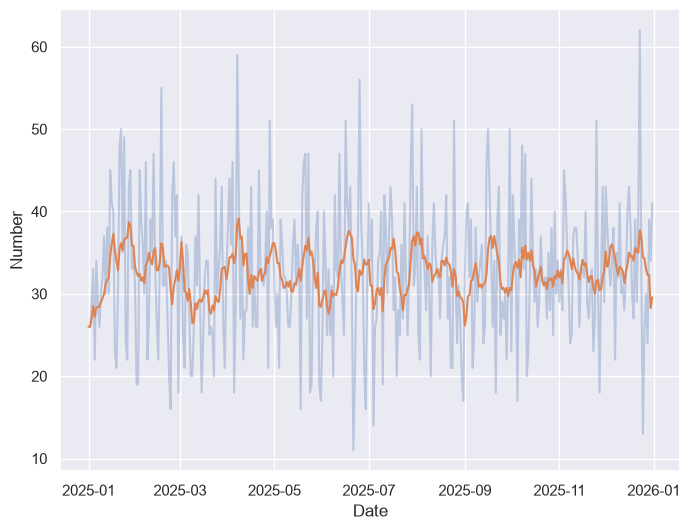

In [19]:
sns.lineplot(x = "Date", y = "Number", data = theft_by_date, alpha = 0.3)
sns.lineplot(x = "Date", y = "Weekly_Avg", data = theft_by_date)

## Exercises

Data APIs are complicated topics and we're only scratching the surface here of what you can do with them.  In turn, your exercises for this assignment will be a little different.  

Your job here is to replicate the above analysis for __another type of offense__ and __optionally another time period__ in Fort Worth.  Visit the Fort Worth dataset on the web here: https://data.fortworthtexas.gov/datasets/5acdb612b4654c3abb30e6987db2408b/explore and look at the "Nature of Call" column to see what other options there are.  Some tips: some crimes like murder are relatively rare, so you might be better served choosing an offense that is more frequent.  Also, values in the "Description" column have changed somewhat over time, so be mindful of this when selecting a type of crime.  Finally, the API will return at most 32,000 records in a single call; if you choose a common offense, keep your time period to a year or less.  

What this basically involves is re-using the code I've already written for this assignment, and modifying it slightly for your chosen type of offense and your chosen time period.  To do this, you'll modify the API call at the beginning of the code accordingly.  I want you to get a sense of how you can "change parameters" in an API call, and in turn get different results.  Indeed, an enterprising analysis like this could wrap everything in a function and re-produce analyses by parameterizing these inputs in Python; you don't have to do that here, but hopefully this gives you a sense of why it is useful to write everything out with code.  

To get full credit for this assignment, your results should include responses to the following questions:  

1. How did crime incidents for your chosen offense in your chosen time period vary by city council district?  
2. Draw a chart that shows these variations.  
3. How did crime rates per 1000 residents in your chosen time period vary by city council district for your chosen offense?  
4. Draw a chart that shows variations in rates by council district.  
5. Draw a line chart that shows how incidents of your chosen offense varied by day in the time period that you chose.  
6. In the theft example above, the counts by council district add up to fewer than the number of records the API returned; about 480 thefts have no council district.  Check your own offense: how many of your records are missing a council district?  If you were reporting your results from Questions 1-4, what would you do about these records, and why?  Would your answer change if most of the missing records came from one part of the city?  